In [1]:

print("Welcome to my EV Battery Analytics Project!")


Welcome to my EV Battery Analytics Project!


In [2]:

battery_count = 24
lfp_batteries = 16
nmc_batteries = 8

print("Total Batteries:", battery_count)
print("LFP Batteries:", lfp_batteries)
print("NMC Batteries:", nmc_batteries)


Total Batteries: 24
LFP Batteries: 16
NMC Batteries: 8


In [3]:

# Check analytical libraries

import sys
import pandas as pd
import numpy as np
import matplotlib
import scipy

print("Python version:", sys.version.split()[0])
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Matplotlib version:", matplotlib.__version__)
print("SciPy version:", scipy.__version__)

print("Battery Analytics Environment Ready!")


Python version: 3.9.7
Pandas version: 1.3.4
NumPy version: 1.20.3
Matplotlib version: 3.4.3
SciPy version: 1.7.1
Battery Analytics Environment Ready!


In [4]:

# Load our battery dataset

import pandas as pd

battery = pd.read_csv("battery_master.csv")

print("Battery dataset loaded successfully!")


Battery dataset loaded successfully!


In [5]:

# Load our battery dataset

import pandas as pd

battery = pd.read_csv("battery_master.csv")

print("Battery dataset loaded successfully!")

Battery dataset loaded successfully!


In [6]:

# Load our battery dataset

import pandas as pd

battery = pd.read_csv("battery_master.csv")

print("Battery dataset loaded successfully!")


Battery dataset loaded successfully!


In [7]:

# Loading our battery dataset

import pandas as pd

battery = pd.read_csv("battery_master.csv")

print("Battery dataset loaded successfully!")


Battery dataset loaded successfully!


In [8]:

# Display the first five rows

battery.head()


,battery_id,chemistry,home_site_id,nominal_voltage_v,rated_capacity_ah,rated_energy_kwh,commissioned_date,initial_equivalent_cycles,initial_soh_pct,baseline_resistance_mohm_25c
0,SYN-BAT-001,LFP,SITE-IKEJA,51.2,50,2.560,2025-06-06,300,98.0,53.79
1,SYN-BAT-002,LFP,SITE-YABA,51.2,60,3.072,2025-03-28,366,96.5,53.08
2,SYN-BAT-003,NMC,SITE-LEKKI,50.4,75,3.780,2024-04-20,90,95.0,64.99
3,SYN-BAT-004,LFP,SITE-SURULERE,51.2,50,2.560,2024-11-01,602,93.5,45.06
4,SYN-BAT-005,LFP,SITE-IKEJA,51.2,60,3.072,2025-01-30,463,97.4,57.61


In [9]:

# Check number of rows and columns

print("Rows:", battery.shape[0])
print("Columns:", battery.shape[1])


Rows: 24
Columns: 10


In [10]:

# Count batteries by chemistry

battery["chemistry"].value_counts()


LFP    16
NMC     8
Name: chemistry, dtype: int64

In [11]:

# Inspect dataset structure

battery.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 10 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   battery_id                    24 non-null     object 
 1   chemistry                     24 non-null     object 
 2   home_site_id                  24 non-null     object 
 3   nominal_voltage_v             24 non-null     float64
 4   rated_capacity_ah             24 non-null     int64  
 5   rated_energy_kwh              24 non-null     float64
 6   commissioned_date             24 non-null     object 
 7   initial_equivalent_cycles     24 non-null     int64  
 8   initial_soh_pct               24 non-null     float64
 9   baseline_resistance_mohm_25c  24 non-null     float64
dtypes: float64(4), int64(2), object(4)
memory usage: 2.0+ KB


In [12]:

# Check missing values in each column

battery.isnull().sum()


battery_id                      0
chemistry                       0
home_site_id                    0
nominal_voltage_v               0
rated_capacity_ah               0
rated_energy_kwh                0
commissioned_date               0
initial_equivalent_cycles       0
initial_soh_pct                 0
baseline_resistance_mohm_25c    0
dtype: int64

In [13]:

# Check for duplicate battery IDs

duplicates = battery["battery_id"].duplicated().sum()

print("Duplicate Battery IDs:", duplicates)


Duplicate Battery IDs: 0


In [14]:

# Summary statistics for numeric columns

battery.describe()


,nominal_voltage_v,rated_capacity_ah,rated_energy_kwh,initial_equivalent_cycles,initial_soh_pct,baseline_resistance_mohm_25c
count,24.000000,24.000000,24.000000,24.000000,24.000000,24.000000
mean,50.933333,61.666667,3.137333,400.250000,93.979167,50.893750
std,0.385235,10.494995,0.510959,167.175838,4.164966,6.231985
min,50.400000,50.000000,2.560000,90.000000,80.400000,38.650000
25%,50.400000,50.000000,2.560000,312.000000,92.300000,46.585000
50%,51.200000,60.000000,3.072000,404.000000,94.850000,51.825000
75%,51.200000,75.000000,3.780000,522.500000,97.150000,55.200000
max,51.200000,75.000000,3.780000,637.000000,98.600000,64.990000


In [15]:

# Convert commissioning dates

battery["commissioned_date"] = pd.to_datetime(
    battery["commissioned_date"],
    errors="coerce"
)

print("New date data type:")
print(battery["commissioned_date"].dtype)

print("\nFirst five commissioning dates:")
print(battery["commissioned_date"].head())


New date data type:
datetime64[ns]

First five commissioning dates:
0   2025-06-06
1   2025-03-28
2   2024-04-20
3   2024-11-01
4   2025-01-30
Name: commissioned_date, dtype: datetime64[ns]


In [16]:

# Check for invalid commissioning dates

invalid_dates = battery["commissioned_date"].isnull().sum()

print("Invalid commissioning dates:", invalid_dates)


Invalid commissioning dates: 0


In [17]:

# Calculate battery age at the observation date

analysis_date = pd.Timestamp("2026-10-28")

battery["BatteryAgeYears"] = (
    (analysis_date - battery["commissioned_date"]).dt.days
    / 365.25
).round(2)

# Display selected columns
battery[
    ["battery_id", "chemistry",
     "commissioned_date", "BatteryAgeYears"]
].head(10)


,battery_id,chemistry,commissioned_date,BatteryAgeYears
0,SYN-BAT-001,LFP,2025-06-06,1.39
1,SYN-BAT-002,LFP,2025-03-28,1.59
2,SYN-BAT-003,NMC,2024-04-20,2.52
3,SYN-BAT-004,LFP,2024-11-01,1.99
4,SYN-BAT-005,LFP,2025-01-30,1.74
5,SYN-BAT-006,NMC,2025-06-16,1.37
6,SYN-BAT-007,LFP,2024-04-28,2.50
7,SYN-BAT-008,LFP,2025-03-11,1.63
8,SYN-BAT-009,NMC,2025-08-27,1.17
9,SYN-BAT-010,LFP,2025-08-15,1.20


In [18]:

# Average battery age by chemistry

average_age = battery.groupby(
    "chemistry"
)["BatteryAgeYears"].mean().round(2)

print(average_age)


chemistry
LFP    1.76
NMC    2.07
Name: BatteryAgeYears, dtype: float64


In [19]:

# Identify the oldest battery

oldest_battery = battery.loc[
    battery["BatteryAgeYears"].idxmax()
]

print("Oldest Battery:", oldest_battery["battery_id"])
print("Chemistry:", oldest_battery["chemistry"])
print("Age:", oldest_battery["BatteryAgeYears"], "years")


Oldest Battery: SYN-BAT-021
Chemistry: NMC
Age: 2.87 years


In [20]:

# Import daily battery telemetry

daily = pd.read_csv(
    "daily_telemetry.csv",
    parse_dates=["reading_date"]
)

print("Daily records:", daily.shape[0])
print("Columns:", daily.shape[1])
print("Unique batteries:", daily["battery_id"].nunique())

daily.head()


Daily records: 2880
Columns: 17
Unique batteries: 24


,reading_date,battery_id,site_id,soc_start_pct,soc_end_pct,distance_km,discharge_energy_kwh,charge_energy_kwh,estimated_capacity_ah,avg_temp_c,max_temp_c,cell_voltage_delta_mv,resistance_mohm_25c,equivalent_full_cycles_cum,charge_sessions,fast_charge_sessions,bms_warning_flag
0,2026-07-01,SYN-BAT-001,SITE-IKEJA,68.3,49.8,16.2,0.890,0.425,48.961,27.3,32.2,21.7,53.31,300.348,1,0,0
1,2026-07-02,SYN-BAT-001,SITE-IKEJA,49.8,43.5,28.4,1.719,1.560,49.009,31.2,35.6,14.3,54.30,301.019,1,0,0
2,2026-07-03,SYN-BAT-001,SITE-IKEJA,43.5,50.6,24.7,1.330,1.507,49.025,27.8,32.7,18.8,53.61,301.539,1,0,0
3,2026-07-04,SYN-BAT-001,SITE-IKEJA,50.6,44.3,11.4,0.659,0.501,48.978,29.3,32.4,14.0,53.82,301.796,1,0,0
4,2026-07-05,SYN-BAT-001,SITE-IKEJA,44.3,73.1,34.8,1.809,2.531,49.000,30.8,38.4,19.4,53.78,302.503,2,1,0


In [21]:

# Join telemetry with battery master

merged = pd.merge(
    daily,
    battery,
    on="battery_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

print("Merged records:", len(merged))

print(merged["_merge"].value_counts())


Merged records: 2880
both          2880
left_only        0
right_only       0
Name: _merge, dtype: int64


In [22]:

# Calculate battery State of Health

merged["SOH_pct"] = (
    100 * merged["estimated_capacity_ah"]
    / merged["rated_capacity_ah"]
).round(2)

merged[
    ["battery_id", "reading_date",
     "chemistry", "SOH_pct"]
].head(10)


,battery_id,reading_date,chemistry,SOH_pct
0,SYN-BAT-001,2026-07-01,LFP,97.92
1,SYN-BAT-001,2026-07-02,LFP,98.02
2,SYN-BAT-001,2026-07-03,LFP,98.05
3,SYN-BAT-001,2026-07-04,LFP,97.96
4,SYN-BAT-001,2026-07-05,LFP,98.00
5,SYN-BAT-001,2026-07-06,LFP,98.01
6,SYN-BAT-001,2026-07-07,LFP,97.99
7,SYN-BAT-001,2026-07-08,LFP,97.86
8,SYN-BAT-001,2026-07-09,LFP,97.93
9,SYN-BAT-001,2026-07-10,LFP,97.90


In [23]:

# Obtain the latest observation per battery

latest = (
    merged.sort_values("reading_date")
    .drop_duplicates(
        "battery_id",
        keep="last"
    )
)

print("Total batteries:", len(latest))

print(
    latest[
        latest["battery_id"].isin(
            ["SYN-BAT-018", "SYN-BAT-020"]
        )
    ][["battery_id", "SOH_pct"]]
)


Total batteries: 24
       battery_id  SOH_pct
2159  SYN-BAT-018    86.56
2399  SYN-BAT-020    79.33


In [24]:

print(
    "Average Fleet SOH:",
    round(latest["SOH_pct"].mean(), 2),
    "%"
)


Average Fleet SOH: 93.3 %


In [25]:

# Calculate precise SOH

merged["SOH_raw"] = (
    100.0 * merged["estimated_capacity_ah"]
    / merged["rated_capacity_ah"]
)

print("Precise SOH calculation completed!")

merged[
    ["battery_id", "reading_date", "SOH_raw"]
].head()


Precise SOH calculation completed!


,battery_id,reading_date,SOH_raw
0,SYN-BAT-001,2026-07-01,97.922
1,SYN-BAT-001,2026-07-02,98.018
2,SYN-BAT-001,2026-07-03,98.050
3,SYN-BAT-001,2026-07-04,97.956
4,SYN-BAT-001,2026-07-05,98.000


In [26]:

# Sort observations by battery and date

ordered = merged.sort_values(
    ["battery_id", "reading_date"]
)

# Group records by battery

history = ordered.groupby(
    "battery_id",
    as_index=False
).agg(
    chemistry=("chemistry", "first"),
    InitialSOH=("SOH_raw", "first"),
    LatestSOH=("SOH_raw", "last"),
    InitialEFC=("equivalent_full_cycles_cum", "first"),
    LatestEFC=("equivalent_full_cycles_cum", "last")
)

print("Batteries analysed:", len(history))

history.head()


Batteries analysed: 24


,battery_id,chemistry,InitialSOH,LatestSOH,InitialEFC,LatestEFC
0,SYN-BAT-001,LFP,97.922000,97.430000,300.348,351.332
1,SYN-BAT-002,LFP,96.391667,95.953333,366.396,417.932
2,SYN-BAT-003,NMC,95.093333,94.380000,90.417,139.976
3,SYN-BAT-004,LFP,93.494000,92.944000,602.367,653.389
4,SYN-BAT-005,LFP,97.518333,96.975000,463.391,511.688


In [27]:

# Calculate SOH decline

history["SOHDecline_pp"] = (
    history["InitialSOH"]
    - history["LatestSOH"]
)

# Calculate additional cycling during observation

history["ObservedEFC"] = (
    history["LatestEFC"]
    - history["InitialEFC"]
)

# Calculate degradation per 100 EFC

history["DeclinePer100EFC"] = (
    100 * history["SOHDecline_pp"]
    / history["ObservedEFC"].replace(0, np.nan)
)

print("Degradation calculations completed!")


Degradation calculations completed!


In [28]:

# Rank batteries by degradation rate

ranking = history.sort_values(
    "DeclinePer100EFC",
    ascending=False
)

ranking[
    ["battery_id", "chemistry",
     "SOHDecline_pp", "ObservedEFC",
     "DeclinePer100EFC"]
].head(10).round(3)


,battery_id,chemistry,SOHDecline_pp,ObservedEFC,DeclinePer100EFC
17,SYN-BAT-018,NMC,1.305,46.148,2.829
19,SYN-BAT-020,LFP,1.012,43.881,2.305
6,SYN-BAT-007,LFP,0.870,46.799,1.859
8,SYN-BAT-009,NMC,0.873,51.202,1.706
14,SYN-BAT-015,NMC,0.789,46.308,1.705
23,SYN-BAT-024,NMC,0.903,53.588,1.684
5,SYN-BAT-006,NMC,0.855,51.365,1.664
11,SYN-BAT-012,NMC,0.835,55.295,1.509
2,SYN-BAT-003,NMC,0.713,49.559,1.439
13,SYN-BAT-014,LFP,0.692,51.647,1.339


In [29]:

# Importing Matplotlib

import matplotlib.pyplot as plt

print("Matplotlib is ready!")


Matplotlib is ready!


In [30]:

# Select the top 10 batteries by degradation rate

top10 = ranking.head(10).copy()

# Arrange values for a horizontal bar chart
top10 = top10.sort_values(
    "DeclinePer100EFC",
    ascending=True
)

top10[
    ["battery_id", "DeclinePer100EFC"]
]


,battery_id,DeclinePer100EFC
13,SYN-BAT-014,1.339219
2,SYN-BAT-003,1.439362
11,SYN-BAT-012,1.509479
5,SYN-BAT-006,1.663909
23,SYN-BAT-024,1.684457
14,SYN-BAT-015,1.704529
8,SYN-BAT-009,1.705663
6,SYN-BAT-007,1.859014
19,SYN-BAT-020,2.305478
17,SYN-BAT-018,2.828581


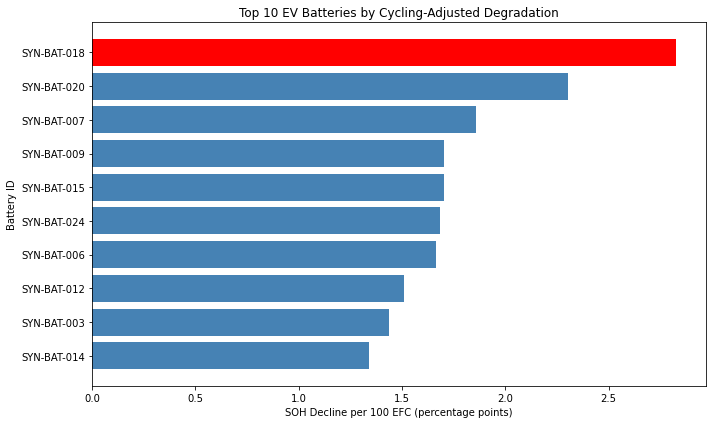

In [31]:

# Create battery degradation bar chart

plt.figure(figsize=(10, 6))

plt.barh(
    top10["battery_id"],
    top10["DeclinePer100EFC"],
    
color=[
    "red" if battery_id == "SYN-BAT-018"
    else "steelblue"
    for battery_id in top10["battery_id"]
]

)

plt.title(
    "Top 10 EV Batteries by Cycling-Adjusted Degradation"
)

plt.xlabel("SOH Decline per 100 EFC (percentage points)")
plt.ylabel("Battery ID")

plt.tight_layout()
plt.show()


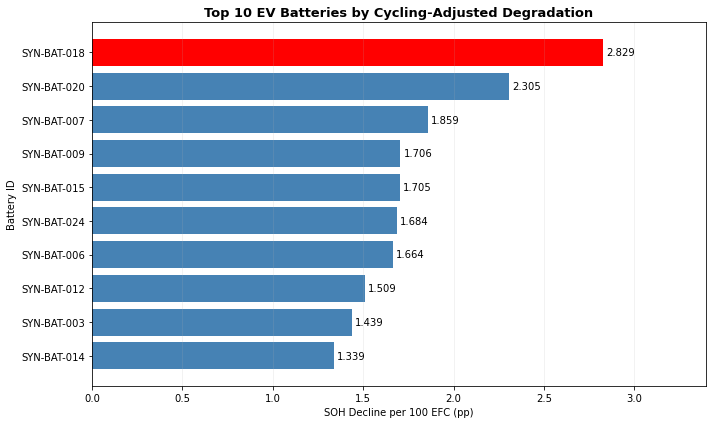

In [32]:

# Final formatted battery degradation chart

plt.figure(figsize=(10, 6))

colors = [
    "red" if battery_id == "SYN-BAT-018"
    else "steelblue"
    for battery_id in top10["battery_id"]
]

bars = plt.barh(
    top10["battery_id"],
    top10["DeclinePer100EFC"],
    color=colors
)

plt.bar_label(
    bars,
    fmt="%.3f",
    padding=3
)

plt.title(
    "Top 10 EV Batteries by Cycling-Adjusted Degradation",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("SOH Decline per 100 EFC (pp)")
plt.ylabel("Battery ID")

plt.xlim(0, top10["DeclinePer100EFC"].max() * 1.2)

plt.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()



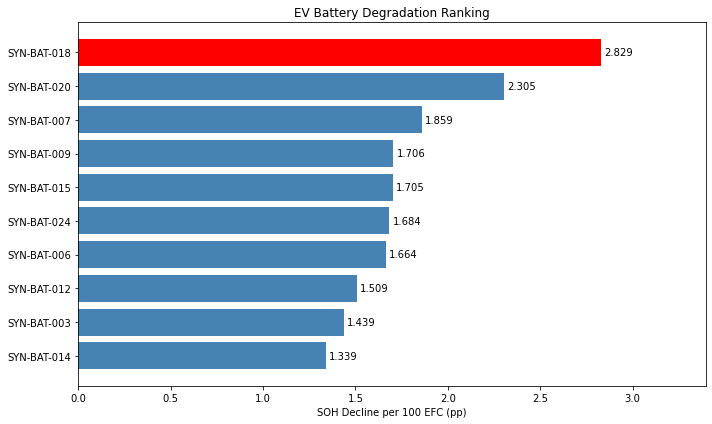

In [33]:

# Save chart as a high-resolution PNG

plt.figure(figsize=(10, 6))

bars = plt.barh(
    top10["battery_id"],
    top10["DeclinePer100EFC"],
    color=colors
)

plt.bar_label(bars, fmt="%.3f", padding=3)

plt.title("EV Battery Degradation Ranking")
plt.xlabel("SOH Decline per 100 EFC (pp)")
plt.xlim(0, top10["DeclinePer100EFC"].max() * 1.2)

plt.tight_layout()

plt.savefig(
    "EV_Battery_Degradation_Ranking.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [34]:

# Comparing degradation by chemistry

chemistry_summary = (
    history.groupby("chemistry")
    .agg(
        BatteryCount=("battery_id", "count"),
        AverageDegradation=("DeclinePer100EFC", "mean"),
        MedianDegradation=("DeclinePer100EFC", "median")
    )
    .reset_index()
)

chemistry_summary = chemistry_summary.round(3)

chemistry_summary


,chemistry,BatteryCount,AverageDegradation,MedianDegradation
0,LFP,16,1.147,1.074
1,NMC,8,1.728,1.674


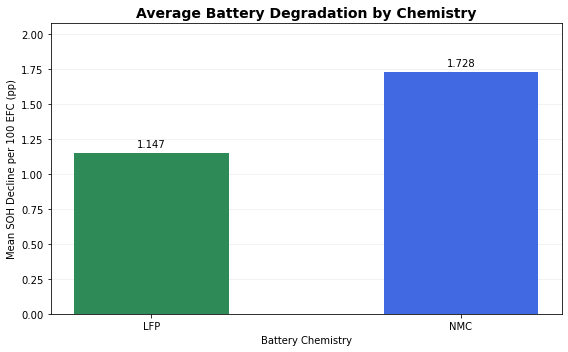

In [35]:

# Compare LFP and NMC average degradation

import matplotlib.pyplot as plt

colors = [
    "seagreen" if chemistry == "LFP"
    else "royalblue"
    for chemistry in chemistry_summary["chemistry"]
]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    chemistry_summary["chemistry"],
    chemistry_summary["AverageDegradation"],
    color=colors,
    width=0.5
)

ax.bar_label(
    bars,
    fmt="%.3f",
    padding=4
)

ax.set_title(
    "Average Battery Degradation by Chemistry",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Battery Chemistry")
ax.set_ylabel("Mean SOH Decline per 100 EFC (pp)")

ax.set_ylim(
    0,
    chemistry_summary["AverageDegradation"].max() * 1.2
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


In [36]:

# Calculating chemistry degradation difference

lfp_rate = chemistry_summary.loc[
    chemistry_summary["chemistry"] == "LFP",
    "AverageDegradation"
].iloc[0]

nmc_rate = chemistry_summary.loc[
    chemistry_summary["chemistry"] == "NMC",
    "AverageDegradation"
].iloc[0]

difference = nmc_rate - lfp_rate

print("LFP mean degradation:", lfp_rate)
print("NMC mean degradation:", nmc_rate)
print("Difference:", round(difference, 3), "pp per 100 EFC")


LFP mean degradation: 1.147
NMC mean degradation: 1.728
Difference: 0.581 pp per 100 EFC


In [37]:

plt.savefig(
    "Battery_Chemistry_Degradation_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)


<Figure size 432x288 with 0 Axes>

In [38]:

# Loading charging events

events = pd.read_csv(
    "charge_events.csv",
    parse_dates=["event_datetime"]
)

print("Charging events:", len(events))
print("Unique batteries:", events["battery_id"].nunique())

events.head()


Charging events: 3024
Unique batteries: 24


,charge_event_id,event_datetime,battery_id,site_id,charge_mode,energy_into_pack_kwh,duration_min,charge_end_temp_c
0,CHG-000001,2026-07-01 10:14:00,SYN-BAT-001,SITE-IKEJA,Standard,0.425,29,31.4
1,CHG-000002,2026-07-02 09:03:00,SYN-BAT-001,SITE-IKEJA,Standard,1.560,88,32.5
2,CHG-000003,2026-07-03 13:34:00,SYN-BAT-001,SITE-IKEJA,Standard,1.507,66,31.7
3,CHG-000004,2026-07-04 10:45:00,SYN-BAT-001,SITE-IKEJA,Standard,0.501,28,30.6
4,CHG-000005,2026-07-05 11:21:00,SYN-BAT-001,SITE-IKEJA,Fast,1.058,27,35.8


In [39]:

# Count high-temperature days per battery

daily["HighTempFlag"] = (
    daily["max_temp_c"] >= 45
).astype(int)

temperature = (
    daily.groupby("battery_id")["HighTempFlag"]
    .sum()
    .reset_index(name="HighTempDays")
)

temperature.head()


,battery_id,HighTempDays
0,SYN-BAT-001,0
1,SYN-BAT-002,0
2,SYN-BAT-003,0
3,SYN-BAT-004,19
4,SYN-BAT-005,0


In [40]:

# Fast-charging share for each battery

events["FastFlag"] = (
    events["charge_mode"] == "Fast"
).astype(int)

charging = (
    events.groupby("battery_id")["FastFlag"]
    .mean()
    .mul(100)
    .reset_index(name="FastChargePct")
)

charging.head()


,battery_id,FastChargePct
0,SYN-BAT-001,25.600000
1,SYN-BAT-002,33.884298
2,SYN-BAT-003,32.800000
3,SYN-BAT-004,35.483871
4,SYN-BAT-005,31.623932


In [41]:

# Merge battery-level analytical measures

drivers = (
    history[
        ["battery_id", "chemistry", "DeclinePer100EFC"]
    ]
    .merge(
        battery[["battery_id", "BatteryAgeYears"]],
        on="battery_id",
        validate="one_to_one"
    )
    .merge(
        temperature,
        on="battery_id",
        validate="one_to_one"
    )
    .merge(
        charging,
        on="battery_id",
        validate="one_to_one"
    )
)

print("Batteries analysed:", len(drivers))
print("Missing values:", drivers.isnull().sum().sum())

drivers.head()


Batteries analysed: 24
Missing values: 0


,battery_id,chemistry,DeclinePer100EFC,BatteryAgeYears,HighTempDays,FastChargePct
0,SYN-BAT-001,LFP,0.965009,1.39,0,25.600000
1,SYN-BAT-002,LFP,0.850538,1.59,0,33.884298
2,SYN-BAT-003,NMC,1.439362,2.52,0,32.800000
3,SYN-BAT-004,LFP,1.077966,1.99,19,35.483871
4,SYN-BAT-005,LFP,1.124984,1.74,0,31.623932


In [42]:

# Chemistry-specific Pearson correlations

results = []

groups = [
    ("Full Fleet", drivers),
    ("LFP", drivers[drivers["chemistry"] == "LFP"]),
    ("NMC", drivers[drivers["chemistry"] == "NMC"])
]

for group_name, data in groups:

    results.append({
        "Group": group_name,
        "Batteries": len(data),

        "Temperature_r":
            data["HighTempDays"].corr(
                data["DeclinePer100EFC"]
            ),

        "Age_r":
            data["BatteryAgeYears"].corr(
                data["DeclinePer100EFC"]
            ),

        "Charging_r":
            data["FastChargePct"].corr(
                data["DeclinePer100EFC"]
            )
    })

correlation_results = pd.DataFrame(results)

correlation_results.round(3)


,Group,Batteries,Temperature_r,Age_r,Charging_r
0,Full Fleet,24,0.183,0.062,-0.088
1,LFP,16,-0.133,0.005,0.276
2,NMC,8,0.947,-0.311,-0.292


In [43]:

# NMC temperature correlation before and after
# excluding BAT-018

nmc = drivers[
    drivers["chemistry"] == "NMC"
]

nmc_without_018 = nmc[
    nmc["battery_id"] != "SYN-BAT-018"
]

print(
    "Before exclusion:",
    round(
        nmc["HighTempDays"].corr(
            nmc["DeclinePer100EFC"]
        ), 3
    )
)

print(
    "Unique temperature exposure values after exclusion:",
    nmc_without_018["HighTempDays"].unique()
)

if nmc_without_018["HighTempDays"].nunique() < 2:
    print("After exclusion: Correlation undefined")
else:
    print(
        nmc_without_018["HighTempDays"].corr(
            nmc_without_018["DeclinePer100EFC"]
        )
    )


Before exclusion: 0.947
Unique temperature exposure values after exclusion: [0]
After exclusion: Correlation undefined


In [44]:

# Preparing chemistry correlations

chart_data = (
    correlation_results
    .set_index("Group")
    .loc[
        ["LFP", "NMC"],
        ["Temperature_r", "Age_r", "Charging_r"]
    ]
    .T
)

# Rename the axis categories
chart_data.index = [
    "High-temperature days",
    "Battery age",
    "Fast charging"
]

chart_data.round(3)


Group,LFP,NMC
High-temperature days,-0.133,0.947
Battery age,0.005,-0.311
Fast charging,0.276,-0.292


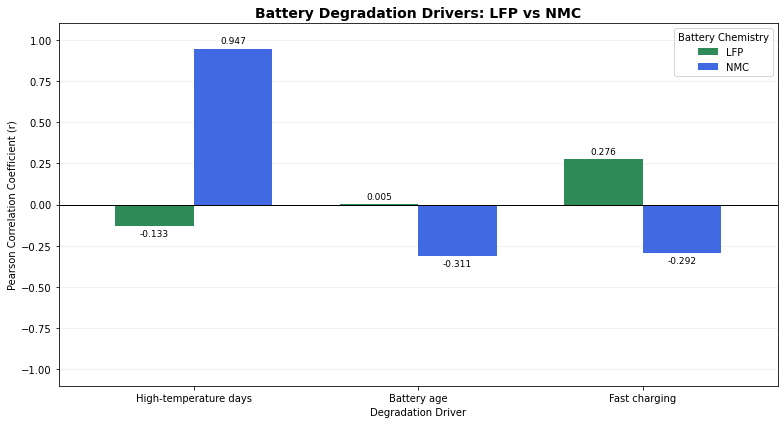

In [45]:

# Lesson 11 - Correlation comparison chart

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 6))

chart_data.plot(
    kind="bar",
    ax=ax,
    color=["seagreen", "royalblue"],
    width=0.7
)

# Add a zero-reference line
ax.axhline(
    y=0,
    color="black",
    linewidth=1
)

# Add chart title and axis labels
ax.set_title(
    "Battery Degradation Drivers: LFP vs NMC",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Degradation Driver")
ax.set_ylabel("Pearson Correlation Coefficient (r)")

# Correlation ranges from -1 to +1
ax.set_ylim(-1.1, 1.1)

# Improve readability
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Battery Chemistry")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)


# Display correlation coefficients on each bar


# Display correlation coefficients on each bar

for bars in ax.containers:
    ax.bar_label(
        bars,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )

plt.tight_layout()


plt.savefig(
    "Battery_Chemistry_Correlation_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()


In [46]:

# Importing statistical functions

from scipy.stats import pearsonr

print("SciPy statistical analysis ready!")


SciPy statistical analysis ready!


In [47]:

# Full-fleet temperature correlation and p-value

r, p = pearsonr(
    drivers["HighTempDays"],
    drivers["DeclinePer100EFC"]
)

print("Pearson r:", round(r, 3))
print("p-value:", round(p, 4))

if p < 0.05:
    print("Statistically significant under test assumptions")
else:
    print("Not statistically significant at the 5% level")


Pearson r: 0.183
p-value: 0.3921
Not statistically significant at the 5% level


In [48]:

# Calculate Pearson r and p-values by chemistry

driver_columns = {
    "Temperature": "HighTempDays",
    "Battery age": "BatteryAgeYears",
    "Fast charging": "FastChargePct"
}

groups = {
    "Full fleet": drivers,
    "LFP": drivers[drivers["chemistry"] == "LFP"],
    "NMC": drivers[drivers["chemistry"] == "NMC"]
}

results = []

for group_name, data in groups.items():
    for driver_name, column in driver_columns.items():

        x = data[column]
        y = data["DeclinePer100EFC"]

        # Correlation needs variation in both variables
        if x.nunique() < 2 or y.nunique() < 2:
            r, p = np.nan, np.nan
        else:
            r, p = pearsonr(x, y)

        results.append({
            "Group": group_name,
            "Driver": driver_name,
            "Batteries": len(data),
            "Pearson_r": r,
            "p_value": p
        })

stats = pd.DataFrame(results)

# Display readable results
display_stats = stats.copy()

display_stats["Pearson_r"] = (
    display_stats["Pearson_r"].round(3)
)

display_stats["p_value"] = (
    display_stats["p_value"].round(5)
)

display_stats


,Group,Driver,Batteries,Pearson_r,p_value
0,Full fleet,Temperature,24,0.183,0.39206
1,Full fleet,Battery age,24,0.062,0.77435
2,Full fleet,Fast charging,24,-0.088,0.68294
3,LFP,Temperature,16,-0.133,0.62374
4,LFP,Battery age,16,0.005,0.98596
5,LFP,Fast charging,16,0.276,0.30111
6,NMC,Temperature,8,0.947,0.00035
7,NMC,Battery age,8,-0.311,0.45282
8,NMC,Fast charging,8,-0.292,0.48282


In [49]:

# Exact NMC permutation exercise

nmc = drivers[
    drivers["chemistry"] == "NMC"
].copy()

x = nmc["HighTempDays"].to_numpy()
y = nmc["DeclinePer100EFC"].to_numpy()

observed_r, parametric_p = pearsonr(x, y)

possible_rs = []

for i in range(len(nmc)):

    trial_x = np.zeros(len(nmc))

    # Assign the single exposure to position i
    trial_x[i] = x.max()

    trial_r, _ = pearsonr(trial_x, y)

    possible_rs.append(trial_r)

# Two-sided permutation p-value
exact_p = np.mean(
    np.abs(possible_rs) >= abs(observed_r) - 1e-12
)

print("Observed Pearson r:", round(observed_r, 3))
print("Standard Pearson p:", round(parametric_p, 5))
print("Exact permutation p:", round(exact_p, 3))
print("Possible exposure assignments:", len(possible_rs))


Observed Pearson r: 0.947
Standard Pearson p: 0.00035
Exact permutation p: 0.125
Possible exposure assignments: 8


### Statistical Validation Findings

Python SciPy analysis reproduced the battery-degradation correlations previously obtained in Power BI.

The full fleet showed a weak positive association between high-temperature days and cycling-adjusted degradation (r = 0.183, p = 0.392).

The NMC subgroup showed a strong positive Pearson correlation (r = 0.947, standard p ≈ 0.00035). However, only one NMC battery, SYN-BAT-018, recorded high-temperature exposure. Removing this battery made the correlation undefined.

An exact conditional permutation exercise yielded p = 0.125, demonstrating the sensitivity of statistical inference to the data structure and testing assumptions.

**Conclusion:** The NMC temperature relationship is an exploratory signal requiring further observations, not proof of a fleet-wide causal effect. The synthetic dataset is not suitable for real-world battery-failure conclusions.

In [50]:

# Lesson 13 - Prepare NMC data

nmc = drivers[
    drivers["chemistry"] == "NMC"
].copy()

nmc_without_018 = nmc[
    nmc["battery_id"] != "SYN-BAT-018"
].copy()

print("NMC batteries:", len(nmc))
print("After excluding BAT-018:", len(nmc_without_018))

nmc[
    ["battery_id", "HighTempDays", "DeclinePer100EFC"]
]


NMC batteries: 8
After excluding BAT-018: 7


,battery_id,HighTempDays,DeclinePer100EFC
2,SYN-BAT-003,0,1.439362
5,SYN-BAT-006,0,1.663909
8,SYN-BAT-009,0,1.705663
11,SYN-BAT-012,0,1.509479
14,SYN-BAT-015,0,1.704529
17,SYN-BAT-018,15,2.828581
20,SYN-BAT-021,0,1.289656
23,SYN-BAT-024,0,1.684457


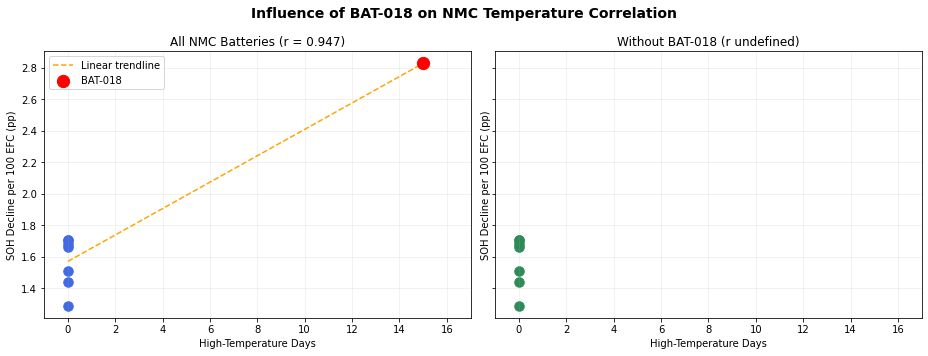

In [51]:

# Comparing NMC temperature relationships
# Before and after excluding BAT-018

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5),
    sharex=True,
    sharey=True
)

# LEFT: All eight NMC batteries
axes[0].scatter(
    nmc["HighTempDays"],
    nmc["DeclinePer100EFC"],
    color="royalblue",
    s=90
)

# Highlight BAT-018
bat018 = nmc[
    nmc["battery_id"] == "SYN-BAT-018"
]

axes[0].scatter(
    bat018["HighTempDays"],
    bat018["DeclinePer100EFC"],
    color="red",
    s=150,
    label="BAT-018",
    zorder=3
)

# Add trendline to full NMC data
slope, intercept = np.polyfit(
    nmc["HighTempDays"],
    nmc["DeclinePer100EFC"],
    1
)

x_line = np.linspace(
    nmc["HighTempDays"].min(),
    nmc["HighTempDays"].max(),
    100
)

axes[0].plot(
    x_line,
    slope * x_line + intercept,
    color="orange",
    linestyle="--",
    label="Linear trendline"
)

axes[0].set_title(
    "All NMC Batteries (r = 0.947)"
)

axes[0].legend()

# RIGHT: Remove BAT-018
axes[1].scatter(
    nmc_without_018["HighTempDays"],
    nmc_without_018["DeclinePer100EFC"],
    color="seagreen",
    s=90
)

axes[1].set_title(
    "Without BAT-018 (r undefined)"
)

# Format both charts
for ax in axes:
    ax.set_xlabel("High-Temperature Days")
    ax.set_ylabel("SOH Decline per 100 EFC (pp)")
    ax.grid(alpha=0.2)
    ax.set_xlim(-1, 17)

plt.suptitle(
    "Influence of BAT-018 on NMC Temperature Correlation",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()


plt.savefig(
    "NMC_BAT018_Influence_Analysis.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()


In [52]:

# Lesson 14 - Leave-one-out sensitivity analysis

from scipy.stats import pearsonr
import pandas as pd

loo_results = []

for excluded_battery in nmc["battery_id"]:

    # Exclude one battery
    remaining = nmc[
        nmc["battery_id"] != excluded_battery
    ]

    # Count exposed batteries
    exposed = (
        remaining["HighTempDays"] > 0
    ).sum()

    # Calculate correlation if possible
    if remaining["HighTempDays"].nunique() < 2:
        r = None
        p = None
    else:
        r, p = pearsonr(
            remaining["HighTempDays"],
            remaining["DeclinePer100EFC"]
        )

    loo_results.append({
        "ExcludedBattery": excluded_battery,
        "BatteriesRemaining": len(remaining),
        "ExposedRemaining": exposed,
        "Pearson_r": r,
        "p_value": p
    })

loo = pd.DataFrame(loo_results)

loo.round(3)


,ExcludedBattery,BatteriesRemaining,ExposedRemaining,Pearson_r,p_value
0,SYN-BAT-003,7,1,0.951,0.001
1,SYN-BAT-006,7,1,0.951,0.001
2,SYN-BAT-009,7,1,0.955,0.001
3,SYN-BAT-012,7,1,0.947,0.001
4,SYN-BAT-015,7,1,0.955,0.001
5,SYN-BAT-018,7,0,NaN,NaN
6,SYN-BAT-021,7,1,0.975,0.000
7,SYN-BAT-024,7,1,0.953,0.001


In [53]:

# Identify cases with undefined correlation

undefined_cases = loo[
    loo["Pearson_r"].isna()
]

print("Undefined correlation cases:")
print(undefined_cases["ExcludedBattery"].tolist())

print(
    "Number of undefined cases:",
    len(undefined_cases)
)


Undefined correlation cases:
['SYN-BAT-018']
Number of undefined cases: 1


### Leave-One-Out Sensitivity Analysis

A leave-one-out sensitivity analysis was conducted on the eight synthetic NMC batteries.

Seven exclusion scenarios retained strong positive temperature–degradation correlations. However, excluding SYN-BAT-018 removed the only battery with high-temperature exposure, leaving the predictor with zero variance and its Pearson correlation undefined.

**Engineering conclusion:** The original NMC temperature correlation is highly dependent on SYN-BAT-018. The observed relationship is an exploratory signal rather than robust evidence of a generalisable fleet-wide association.

The 45°C exposure threshold is illustrative and must not be treated as a manufacturer-approved safety limit.

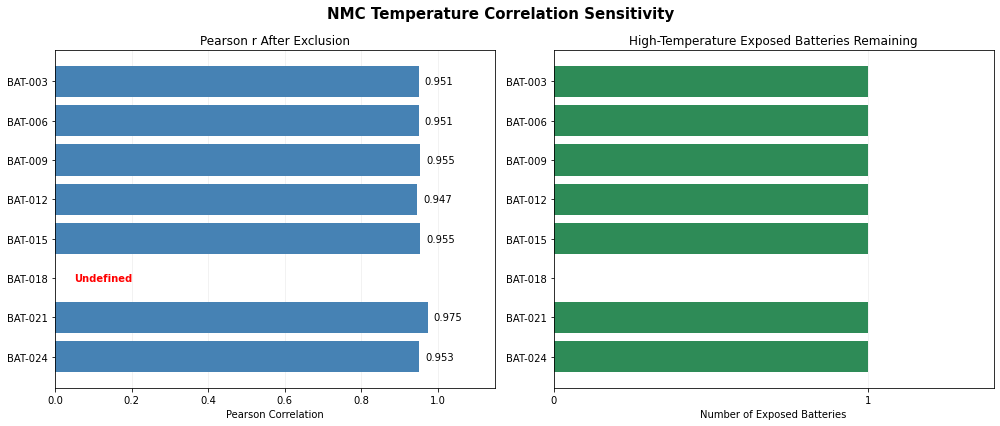

In [54]:

# Lesson 15 - Visualise leave-one-out sensitivity

import matplotlib.pyplot as plt
import numpy as np

# Prepare results
plot_data = loo.sort_values(
    "ExcludedBattery"
).copy()

plot_data["BatteryLabel"] = (
    plot_data["ExcludedBattery"]
    .str.replace("SYN-", "", regex=False)
)

y = np.arange(len(plot_data))

# Create two panels
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6)
)

# PANEL 1: Pearson correlation
valid = plot_data["Pearson_r"].notna()

axes[0].barh(
    y[valid],
    plot_data.loc[valid, "Pearson_r"],
    color="steelblue"
)

# Label valid correlations
for position, value in zip(
    y[valid],
    plot_data.loc[valid, "Pearson_r"]
):
    axes[0].text(
        value + 0.015,
        position,
        f"{value:.3f}",
        va="center"
    )

# Show undefined correlation as text
for position in y[~valid]:
    axes[0].text(
        0.05,
        position,
        "Undefined",
        color="red",
        va="center",
        fontweight="bold"
    )

axes[0].set_title("Pearson r After Exclusion")
axes[0].set_xlabel("Pearson Correlation")
axes[0].set_xlim(0, 1.15)

# PANEL 2: Exposed batteries remaining
colors = [
    "red" if battery == "SYN-BAT-018"
    else "seagreen"
    for battery in plot_data["ExcludedBattery"]
]

axes[1].barh(
    y,
    plot_data["ExposedRemaining"],
    color=colors
)

axes[1].set_title(
    "High-Temperature Exposed Batteries Remaining"
)
axes[1].set_xlabel("Number of Exposed Batteries")
axes[1].set_xlim(0, 1.4)
axes[1].set_xticks([0, 1])

# Format both panels
for ax in axes:
    ax.set_yticks(y)
    ax.set_yticklabels(plot_data["BatteryLabel"])
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle(
    "NMC Temperature Correlation Sensitivity",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "NMC_Leave_One_Out_Sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Sensitivity Visualisation Findings

The leave-one-out visualisation demonstrates that removing any of the seven NMC batteries other than SYN-BAT-018 retains a strong positive temperature–degradation correlation.

However, excluding SYN-BAT-018 removes the only high-temperature-exposed NMC battery. The temperature predictor then has no variation, and Pearson correlation becomes undefined.

**Engineering implication:** SYN-BAT-018 is a critical investigation candidate, but the observed temperature–degradation association cannot be generalised to the entire NMC fleet without additional evidence.

Recommended follow-up investigation should consider operating temperature history, cooling effectiveness, charging behaviour, accumulated cycling, battery age and measurement quality.

In [55]:

# Lesson 16 - Validate project datasets

print("BATTERY ANALYTICS DATA VALIDATION")
print("---------------------------------")

print("Battery master records:", len(battery))
print("Daily telemetry records:", len(daily))
print("Charging events:", len(events))
print("Batteries in analytical model:", len(drivers))

assert len(battery) == 24, "Unexpected battery count"
assert len(daily) == 2880, "Unexpected telemetry count"
assert len(events) == 3024, "Unexpected charging event count"

assert battery["battery_id"].is_unique, \
    "Duplicate battery IDs detected"

assert daily["battery_id"].isin(
    battery["battery_id"]
).all(), "Unmatched telemetry battery IDs"

assert len(drivers) == 24, \
    "Battery analytical model is incomplete"

print("\nAll validation checks passed!")


BATTERY ANALYTICS DATA VALIDATION
---------------------------------
Battery master records: 24
Daily telemetry records: 2880
Charging events: 3024
Batteries in analytical model: 24

All validation checks passed!


In [56]:

# Create an executive KPI report

fleet_report = pd.DataFrame({
    "KPI": [
        "Total Battery Packs",
        "LFP Battery Packs",
        "NMC Battery Packs",
        "Daily Telemetry Records",
        "Charging Events",
        "Average Latest SOH (%)"
    ],

    "Value": [
        len(battery),
        (battery["chemistry"] == "LFP").sum(),
        (battery["chemistry"] == "NMC").sum(),
        len(daily),
        len(events),
        round(latest["SOH_pct"].mean(), 2)
    ]
})

fleet_report


,KPI,Value
0,Total Battery Packs,24.0
1,LFP Battery Packs,16.0
2,NMC Battery Packs,8.0
3,Daily Telemetry Records,2880.0
4,Charging Events,3024.0
5,Average Latest SOH (%),93.3


In [57]:

# Create chemistry-level performance report

chemistry_report = (
    drivers.groupby("chemistry")
    .agg(
        BatteryCount=("battery_id", "count"),
        MeanDegradation=("DeclinePer100EFC", "mean"),
        MedianDegradation=("DeclinePer100EFC", "median")
    )
    .reset_index()
    .round(3)
)

chemistry_report


,chemistry,BatteryCount,MeanDegradation,MedianDegradation
0,LFP,16,1.147,1.074
1,NMC,8,1.728,1.674


In [58]:

# Export battery analytics reports

from pathlib import Path

# Create output folder
output_folder = Path("EV_Battery_Reports")
output_folder.mkdir(exist_ok=True)

# Save analytical reports
fleet_report.to_csv(
    output_folder / "Fleet_KPI_Summary.csv",
    index=False
)

chemistry_report.to_csv(
    output_folder / "Chemistry_Degradation_Report.csv",
    index=False
)

stats.to_csv(
    output_folder / "Correlation_Statistical_Results.csv",
    index=False
)

loo.to_csv(
    output_folder / "NMC_Sensitivity_Analysis.csv",
    index=False
)

print("Reports exported successfully!")
print("Saved in:", output_folder.resolve())


Reports exported successfully!
Saved in: C:\Users\user\EV_Battery_Reports


In [59]:

# Fix - Recreate statistical results DataFrame

import pandas as pd
import numpy as np
from scipy.stats import pearsonr

driver_columns = {
    "Temperature": "HighTempDays",
    "Battery age": "BatteryAgeYears",
    "Fast charging": "FastChargePct"
}

groups = {
    "Full fleet": drivers,
    "LFP": drivers[drivers["chemistry"] == "LFP"],
    "NMC": drivers[drivers["chemistry"] == "NMC"]
}

results = []

for group_name, data in groups.items():
    for driver_name, column in driver_columns.items():

        x = data[column]
        y = data["DeclinePer100EFC"]

        if x.nunique() < 2 or y.nunique() < 2:
            r, p = np.nan, np.nan
        else:
            r, p = pearsonr(x, y)

        results.append({
            "Group": group_name,
            "Driver": driver_name,
            "Batteries": len(data),
            "Pearson_r": r,
            "p_value": p
        })

stats = pd.DataFrame(results)

print("Statistical DataFrame successfully recreated!")
print("Rows:", len(stats))
print("Columns:", len(stats.columns))

stats.round(4)


Statistical DataFrame successfully recreated!
Rows: 9
Columns: 5


,Group,Driver,Batteries,Pearson_r,p_value
0,Full fleet,Temperature,24,0.1830,0.3921
1,Full fleet,Battery age,24,0.0618,0.7744
2,Full fleet,Fast charging,24,-0.0879,0.6829
3,LFP,Temperature,16,-0.1329,0.6237
4,LFP,Battery age,16,0.0048,0.9860
5,LFP,Fast charging,16,0.2758,0.3011
6,NMC,Temperature,8,0.9475,0.0003
7,NMC,Battery age,8,-0.3114,0.4528
8,NMC,Fast charging,8,-0.2920,0.4828


In [60]:

print("Statistical results:", len(stats))
print("Sensitivity results:", len(loo))


Statistical results: 9
Sensitivity results: 8


In [61]:

# Verify exported CSV files

from pathlib import Path

output_folder = Path("EV_Battery_Reports")

for file in sorted(output_folder.glob("*.csv")):
    print(file.name)

print("\nTotal CSV files:",
      len(list(output_folder.glob("*.csv"))))


Chemistry_Degradation_Report.csv
Correlation_Statistical_Results.csv
Fleet_KPI_Summary.csv
Latest_Battery_SOH_Report.csv
NMC_Sensitivity_Analysis.csv

Total CSV files: 5


In [62]:

# Battery SOH function

def calculate_soh(estimated_capacity, rated_capacity):

    if rated_capacity <= 0:
        raise ValueError("Rated capacity must be positive")

    soh = (estimated_capacity / rated_capacity) * 100

    return round(soh, 2)


# Test the function
result = calculate_soh(40, 50)

print("Battery SOH:", result, "%")


Battery SOH: 80.0 %


In [63]:

# Building reusable latest fleet SOH report

def build_latest_soh_report(battery_df, telemetry_df):

    data = telemetry_df.merge(
        battery_df[
            ["battery_id", "chemistry", "rated_capacity_ah"]
        ],
        on="battery_id",
        how="left",
        validate="many_to_one"
    )

    # Validate before calculating SOH
    if data["rated_capacity_ah"].isna().any():
        raise ValueError("Unmatched battery records found")

    if (data["rated_capacity_ah"] <= 0).any():
        raise ValueError("Invalid rated capacity found")

    data["reading_date"] = pd.to_datetime(
        data["reading_date"]
    )

    data["LatestSOH_pct"] = (
        data["estimated_capacity_ah"]
        / data["rated_capacity_ah"] * 100
    )

    latest_data = (
        data.sort_values(["battery_id", "reading_date"])
        .drop_duplicates("battery_id", keep="last")
    )

    return latest_data[
        ["battery_id", "chemistry",
         "reading_date", "LatestSOH_pct"]
    ].sort_values("battery_id").reset_index(drop=True)


In [64]:

# Generate the latest SOH report

latest_report = build_latest_soh_report(
    battery,
    daily
)

print("Total batteries:", len(latest_report))

print(
    "Average Fleet SOH:",
    round(latest_report["LatestSOH_pct"].mean(), 2),
    "%"
)

latest_report.head()


Total batteries: 24
Average Fleet SOH: 93.3 %


,battery_id,chemistry,reading_date,LatestSOH_pct
0,SYN-BAT-001,LFP,2026-10-28,97.430000
1,SYN-BAT-002,LFP,2026-10-28,95.953333
2,SYN-BAT-003,NMC,2026-10-28,94.380000
3,SYN-BAT-004,LFP,2026-10-28,92.944000
4,SYN-BAT-005,LFP,2026-10-28,96.975000


In [65]:

# Reusable CSV export function

from pathlib import Path

def export_report(dataframe, filename):

    folder = Path("EV_Battery_Reports")
    folder.mkdir(parents=True, exist_ok=True)

    filepath = folder / filename

    dataframe.to_csv(filepath, index=False)

    print("Report saved:", filepath.resolve())

    return filepath


# Export latest fleet SOH report
export_report(
    latest_report,
    "Latest_Battery_SOH_Report.csv"
)


Report saved: C:\Users\user\EV_Battery_Reports\Latest_Battery_SOH_Report.csv


WindowsPath('EV_Battery_Reports/Latest_Battery_SOH_Report.csv')

In [66]:

# Validate selected battery SOH values

selected = latest_report[
    latest_report["battery_id"].isin(
        ["SYN-BAT-018", "SYN-BAT-020"]
    )
].copy()

selected["LatestSOH_pct"] = (
    selected["LatestSOH_pct"].round(2)
)

selected


,battery_id,chemistry,reading_date,LatestSOH_pct
17,SYN-BAT-018,NMC,2026-10-28,86.56
19,SYN-BAT-020,LFP,2026-10-28,79.33
